## NYT macro news → FinBERT → SQL Server

In [2]:
import os, sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv

# Locate the project regardless of the notebook's launch directory.
candidate = Path.cwd().resolve()
PROJECT_ROOT = next(
    p for p in (candidate, *candidate.parents)
    if (p / 'requirements.txt').exists() and (p / 'modelling').exists()
)
sys.path.insert(0, str(PROJECT_ROOT))
load_dotenv(PROJECT_ROOT / '.env')

from modelling.news_pipeline import (
    download_nyt_archive, load_scored_news_to_database,
    monthly_sentiment, score_with_finbert,
)

CACHE_DIR = PROJECT_ROOT / 'data/raw/news/nyt_archive'
FILTERED_PATH = PROJECT_ROOT / 'data/processed/nyt_macro_articles_2007_2023.csv'
SCORED_PATH = PROJECT_ROOT / 'data/processed/nyt_finbert_article_scores.csv'
MONTHLY_PATH = PROJECT_ROOT / 'data/processed/US/nyt_monthly_sentiment_2007_2023.csv'

START_YEAR, END_YEAR = 2007, 2023
NYT_API_KEY = os.getenv('NYT_API_KEY', '').strip()
print('Project root:', PROJECT_ROOT)
print('NYT API key configured:', bool(NYT_API_KEY))
print('FinBERT output path:', repr(str(SCORED_PATH)))

Project root: D:\Master Semester 4\Thesis
NYT API key configured: True
FinBERT output path: 'D:\\Master Semester 4\\Thesis\\data\\processed\\nyt_finbert_article_scores.csv'


**Download and filter**

In [ ]:
if not NYT_API_KEY:
    raise RuntimeError('Add NYT_API_KEY to the project .env file, restart the kernel, and rerun.')

articles = download_nyt_archive(
    api_key=NYT_API_KEY,
    start_year=START_YEAR,
    end_year=END_YEAR,
    cache_dir=CACHE_DIR,
)
FILTERED_PATH.parent.mkdir(parents=True, exist_ok=True)
articles.to_csv(FILTERED_PATH, index=False)
print(f'Saved {len(articles):,} filtered articles to {FILTERED_PATH}')
articles.head(3)

In [ ]:
articles = pd.read_csv(FILTERED_PATH, parse_dates=['published_at', 'news_date'])
articles['month'] = articles['news_date'].dt.to_period('M').dt.to_timestamp()
coverage = articles.groupby('month').size().rename('article_count')
display(coverage.describe().to_frame().T)
display(articles.sample(min(20, len(articles)), random_state=42)[
    ['published_at', 'title', 'matched_macro_terms', 'matched_us_terms', 'news_desk']
])

ax = coverage.plot(figsize=(13, 4), title='NYT retained US macro articles per month')
ax.set_ylabel('Article count')
plt.show()

**FinBERT scoring**

In [3]:
articles = pd.read_csv(FILTERED_PATH)
scored = score_with_finbert(
    articles=articles,
    output_path=SCORED_PATH,
    batch_size=32,  # reduce to 8 or 16 if memory is limited
    checkpoint_every=500,
)
display(scored[['title', 'sentiment_label', 'sentiment_score']].head())
display(scored['sentiment_label'].value_counts(normalize=True).rename('share'))

c:\Users\zahra\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 201/201 [00:00<00:00, 12561.16it/s]


Scored 512/9,447 new articles on cpu.
Scored 1,024/9,447 new articles on cpu.
Scored 1,504/9,447 new articles on cpu.
Scored 2,016/9,447 new articles on cpu.
Scored 2,528/9,447 new articles on cpu.
Scored 3,008/9,447 new articles on cpu.
Scored 3,520/9,447 new articles on cpu.
Scored 4,000/9,447 new articles on cpu.
Scored 4,512/9,447 new articles on cpu.
Scored 5,024/9,447 new articles on cpu.
Scored 5,504/9,447 new articles on cpu.
Scored 6,016/9,447 new articles on cpu.
Scored 6,528/9,447 new articles on cpu.
Scored 7,008/9,447 new articles on cpu.
Scored 7,520/9,447 new articles on cpu.
Scored 8,000/9,447 new articles on cpu.
Scored 8,512/9,447 new articles on cpu.
Scored 9,024/9,447 new articles on cpu.
Scored 9,447/9,447 new articles on cpu.


,title,sentiment_label,sentiment_score
0,Looking Ahead,neutral,-0.113744
1,Economists Cautiously Optimistic About 2007,positive,0.837282
2,Weathering a Storm in Shelter,neutral,-0.167508
3,Dollar’s Skid Puts a Glow on the Euro,negative,-0.902317
4,Singapore: Growth Spurt in Quarter,positive,0.909506


sentiment_label
negative    0.480158
neutral     0.386752
positive    0.133090
Name: share, dtype: float64

**Monthly sentiment dataset**

Saved: D:\Master Semester 4\Thesis\data\processed\US\nyt_monthly_sentiment_2007_2023.csv


,month_date,News_Sentiment,Sentiment_Median,Sentiment_Std,Negative_Share,Article_Count
0,2007-01-01,-0.329116,-0.522036,0.591161,0.578947,38
1,2007-02-01,-0.170357,-0.053693,0.650998,0.450000,40
2,2007-03-01,-0.404710,-0.572544,0.544493,0.568627,51
3,2007-04-01,-0.275370,-0.290138,0.506662,0.466667,30
4,2007-05-01,-0.172399,-0.199209,0.613092,0.457143,35


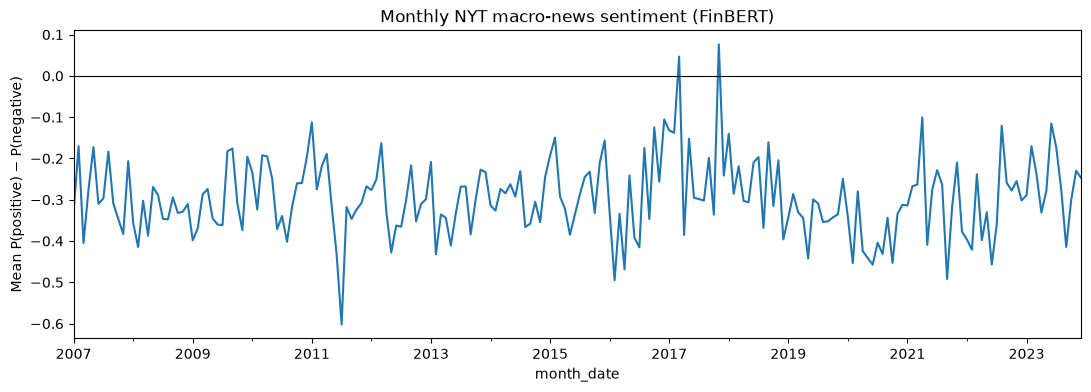

In [4]:
scored = pd.read_csv(SCORED_PATH, parse_dates=['published_at', 'news_date'])
monthly = monthly_sentiment(scored)
MONTHLY_PATH.parent.mkdir(parents=True, exist_ok=True)
monthly.to_csv(MONTHLY_PATH, index=False)
print('Saved:', MONTHLY_PATH)
display(monthly.head())

ax = monthly.plot(x='month_date', y='News_Sentiment', figsize=(13, 4), legend=False,
                  title='Monthly NYT macro-news sentiment (FinBERT)')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('Mean P(positive) − P(negative)')
plt.show()

**Database load**

In [7]:
import urllib.parse
from sqlalchemy import create_engine, text

WRITE_TO_DATABASE = True
ACTIVATE_NYT = True

server = os.getenv('DB_SERVER', 'localhost')
database = os.getenv('DB_DATABASE', 'MacroSentimentDB')
driver = os.getenv('DB_DRIVER', 'ODBC Driver 17 for SQL Server')
connection_string = (
    f'DRIVER={{{driver}}};SERVER={server};DATABASE={database};Trusted_Connection=yes;'
)
engine = create_engine(
    'mssql+pyodbc:///?odbc_connect=' + urllib.parse.quote_plus(connection_string),
    fast_executemany=True,
)

with engine.connect() as connection:
    print(connection.execute(text('SELECT @@SERVERNAME, DB_NAME()')).one())

if WRITE_TO_DATABASE:
    scored = pd.read_csv(SCORED_PATH, parse_dates=['published_at', 'news_date'])
    inserted = load_scored_news_to_database(
        scored, engine, SCORED_PATH, activate_nyt=ACTIVATE_NYT,
    )
    print(f'Inserted {inserted:,} new NYT articles. Active={ACTIVATE_NYT}')
else:
    print('Dry run only: set WRITE_TO_DATABASE=True after reviewing the outputs.')

('Lara', 'MacroSentimentDB')
Inserted 0 new NYT articles. Active=True


In [8]:
# Database verification (read-only)
verification_sql = text('''
SELECT s.source_code, s.source_name, s.is_active, COUNT(n.article_id) AS article_count,
       MIN(n.news_date) AS earliest, MAX(n.news_date) AS latest
FROM core.news_sources s
LEFT JOIN core.daily_news n ON n.source_id = s.source_id
GROUP BY s.source_code, s.source_name, s.is_active
ORDER BY s.source_code
''')
display(pd.read_sql(verification_sql, engine))

,source_code,source_name,is_active,article_count,earliest,latest
0,FINSEN,FinSen Financial Sentiment Dataset,False,15534,2007-06-04,2023-07-16
1,NYT,The New York Times Archive API,True,16455,2007-01-01,2023-12-31
